# What the Benchmarks Say About Predictive Value

**Evidence: Committed research evidence; Synthetic demonstration.** We read saved
summary metrics and historical check states, then use three fictional predictions
to explain the loss function. No estimator is refitted, and no observation-level
historical forecasts are created or independently rescored here.

**Research question:** do bank fundamentals and macro conditions add predictive
information beyond persistent credit losses? Economic plausibility motivates
predictors, but a richer model must be judged against a credible benchmark on the
same target and information set. Mean forecasts and upper quantiles answer
different questions, so their scores are kept separate.

[Previous: data definitions](01_call_reports_to_credit_losses.ipynb) ·
[Project](../README.md) · [Next: C&I stress](03_ci_stress_scenario_walkthrough.ipynb)

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from bankstress.research_guides import repository_root

ROOT = repository_root()
pd.set_option("display.max_columns", 8)
pd.set_option("display.width", 100)
plt.rcParams.update({"figure.figsize": (8, 3.4), "font.size": 10})

import yaml
EVIDENCE = ROOT / "results/evidence"
summary = json.loads((ROOT / "results/summary.json").read_text())
spec = yaml.safe_load((ROOT / "configs/model_specs.yaml").read_text())

## Preserve the arrow of time

The four expanding windows below come from the current specification. The
forecast origin identifies the information set; the target period identifies the
quarter whose loss will be predicted. Bank filings and macro releases follow
their documented availability rules. A usable predictor set permits a forecast;
an observed target is additionally required to score it. Random row splits would
mix later information into an earlier evaluation and obscure changing regimes.

In [2]:
windows = pd.DataFrame(spec["oos_windows"], index=pd.Index(range(1, 5), name="window"))
assert len(windows) == 4
assert (pd.to_datetime(windows.train_end) < pd.to_datetime(windows.test_start)).all()
display(windows)

,train_start,train_end,test_start,test_end
window,,,,
1,2005-01-01,2011-12-31,2012-01-01,2016-12-31
2,2005-01-01,2016-12-31,2017-01-01,2019-12-31
3,2005-01-01,2019-12-31,2020-01-01,2021-12-31
4,2005-01-01,2021-12-31,2022-01-01,2025-12-31


## Start with all eight mean comparisons

The AR benchmark already includes bank effects and lagged losses. Dynamic FE
adds bank controls and segment-specific macro predictors. We pair the saved
equal-observation RMSE by segment and window, require unique rows and equal
sample counts, and inspect the recorded common-key flag. These aggregate files
cannot independently reconstruct the bank/origin/target keys: matching counts
alone would not prove identical observations. The flag reports the historical
check, not a new observation-level validation performed by this notebook.

In [3]:
mean = pd.read_csv(EVIDENCE / "mean_model_comparison.csv")
assert not mean.duplicated(["segment", "window", "model"]).any()
assert mean.common_scoring_keys_verified.eq(True).all()
assert set(mean.model) == {"ar", "dynamic_fe"}
expected = pd.MultiIndex.from_product([["CI", "CRE"], [1, 2, 3, 4]], names=["segment", "window"])
mean_counts = mean.pivot(index=["segment", "window"], columns="model", values="n")
mean_scores = mean.pivot(index=["segment", "window"], columns="model", values="rmse")
assert mean_scores.index.equals(expected)
assert mean_scores.notna().all().all() and mean_counts.notna().all().all()
assert mean_counts.ar.equals(mean_counts.dynamic_fe)
mean_scores["RMSE reduction (%)"] = 100 * (1 - mean_scores.dynamic_fe / mean_scores.ar)
mean_scores.insert(0, "Scored n", mean_counts.ar)
display(mean_scores.round(6))
wins = int((mean_scores.dynamic_fe < mean_scores.ar).sum())
assert wins == summary["dynamic_fe_rmse_wins"] and len(mean_scores) == summary["mean_comparisons"]
display(Markdown(f"Dynamic FE lowers RMSE in **{wins} of {len(mean_scores)}** comparisons. Persistence remains a strong benchmark."))

model           Scored n        ar  dynamic_fe  RMSE reduction (%)
segment window                                                    
CI      1            524  0.009067    0.009666           -6.603629
        2            312  0.005383    0.007777          -44.463953
        3            231  0.005009    0.005699          -13.788160
        4            458  0.004863    0.004828            0.716574
CRE     1            260  0.004497    0.005286          -17.541306
        2            324  0.003668    0.003940           -7.413613
        3            237  0.003000    0.003096           -3.180252
        4            443  0.004076    0.004224           -3.615325

Dynamic FE lowers RMSE in **1 of 8** comparisons. Persistence remains a strong benchmark.

## Match a tail question to its loss function

For a conditional Q90 forecast, an error $u=y-\widehat q_{0.9}$ receives pinball
loss $\rho_{0.9}(u)=\max(0.9u,-0.1u)$. Underestimating the same loss rate is nine
times as costly as overestimating it. This asymmetric objective targets a quantile;
it is not RMSE with a different label. The following decimal-rate examples call
the existing scoring function. A perfect prediction has zero loss, but a Q90
forecast need not equal the realized value on every observation.

In [4]:
from bankstress.tail_validation import pinball_loss

toy = pd.DataFrame({"Actual": [0.03, 0.01, 0.02], "Prediction": [0.02, 0.02, 0.02]},
                   index=["Underprediction", "Overprediction", "Perfect"])
toy["Pinball loss"] = [pinball_loss(pd.Series([a]), pd.Series([p]), 0.9)
                       for a, p in zip(toy.Actual, toy.Prediction)]
np.testing.assert_allclose(toy["Pinball loss"], [0.009, 0.001, 0.0], atol=1e-15)
np.testing.assert_allclose(pinball_loss(toy.Actual, toy.Prediction, 0.9), 0.01 / 3)
display(Markdown("**Synthetic demonstration — decimal annualized rates, tau = 0.9.**"))
display(toy)

**Synthetic demonstration — decimal annualized rates, tau = 0.9.**

,Actual,Prediction,Pinball loss
Underprediction,0.03,0.02,0.009
Overprediction,0.01,0.02,0.001
Perfect,0.02,0.02,0.000


## Compare like quantiles and like prediction versions

Both families below use Q90 and **POST_REARRANGEMENT** predictions. Window 0 is
pooled out-of-sample evidence, not a fifth window. The reduction is one minus
dynamic loss divided by AR loss. We read pooled losses directly, verify their
observation-weighted relationship to window scores, and compare with the saved
summary. Averaging window improvement percentages would give a different, poorly
defined headline because windows have unequal sample sizes and baseline losses.

In [5]:
tail = pd.read_csv(EVIDENCE / "tail_metrics.csv")
q90 = tail.loc[tail.tau.eq(0.9) & tail.model_family.isin(["ar_quantile", "dynamic_quantile"])].copy()
assert not q90.duplicated(["segment", "window", "model_family", "prediction_version"]).any()
assert set(q90.prediction_version) == {"PRE_REARRANGEMENT", "POST_REARRANGEMENT"}
assert q90.common_scoring_keys_verified.eq(True).all()
post = q90.loc[q90.prediction_version.eq("POST_REARRANGEMENT")]
counts = post.pivot(index=["segment", "window"], columns="model_family", values="scored_n")
scores = post.pivot(index=["segment", "window"], columns="model_family", values="pinball_loss")
assert scores.index.equals(pd.MultiIndex.from_product([["CI", "CRE"], range(5)], names=["segment", "window"]))
assert scores.notna().all().all() and counts.ar_quantile.equals(counts.dynamic_quantile)
scores["improvement_pct"] = 100 * (1 - scores.dynamic_quantile / scores.ar_quantile)
reference = pd.DataFrame(summary["q90_pinball_comparison"]).set_index(["segment", "window"]).sort_index()
np.testing.assert_allclose(scores, reference[scores.columns], rtol=1e-10)
for (segment, family), rows in post.groupby(["segment", "model_family"]):
    pooled, individual = rows.loc[rows.window.eq(0)].iloc[0], rows.loc[rows.window.ne(0)]
    assert pooled.scored_n == individual.scored_n.sum()
    np.testing.assert_allclose(pooled.pinball_loss, np.average(individual.pinball_loss, weights=individual.scored_n), rtol=1e-10)
display(scores.join(counts.ar_quantile.rename("Scored n")).round(7))

ar_quantile  dynamic_quantile  improvement_pct  Scored n
segment window                                                          
CI      0          0.001393          0.001357         2.579511      1525
        1          0.001941          0.001903         1.942646       524
        2          0.001123          0.001200        -6.848768       312
        3          0.001034          0.000962         6.893140       231
        4          0.001133          0.001040         8.209321       458
CRE     0          0.000617          0.000584         5.382116      1264
        1          0.000701          0.000721        -2.779415       260
        2          0.000537          0.000517         3.744065       324
        3          0.000510          0.000464         8.950121       237
        4          0.000684          0.000617         9.810755       443

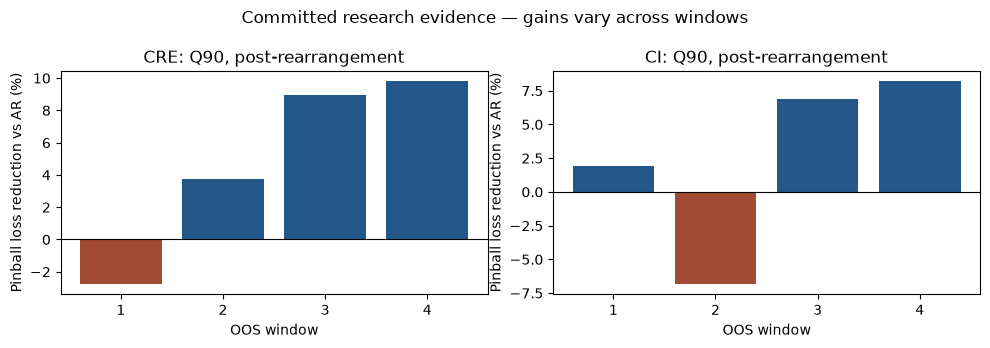

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, segment in zip(axes, ["CRE", "CI"]):
    values = scores.xs(segment).loc[1:4, "improvement_pct"]
    ax.bar(values.index.astype(str), values, color=["#235789" if v > 0 else "#a14b35" for v in values])
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set(title=f"{segment}: Q90, post-rearrangement", xlabel="OOS window", ylabel="Pinball loss reduction vs AR (%)")
fig.suptitle("Committed research evidence — gains vary across windows")
fig.tight_layout()
plt.show()

## A repair is not a broader validation conclusion

Independent quantile fits can cross. Rearrangement sorts a single forecast's
quantiles into order; it does not estimate a nine-quarter loss distribution. The
short pre/post table uses the same version for both competitors. We also report
exceedance: Q90 nominally leaves 10% of outcomes above the forecast. A lower
exceedance rate is not automatically better calibration, and removing crossings
does not establish forecasting skill. No significance test is added here.

In [7]:
pooled = q90.loc[q90.window.eq(0)]
versions = pooled.pivot(index=["segment", "prediction_version"], columns="model_family", values="pinball_loss")
version_n = pooled.pivot(index=["segment", "prediction_version"], columns="model_family", values="scored_n")
assert version_n.notna().all().all() and version_n.ar_quantile.equals(version_n.dynamic_quantile)
assert version_n.groupby(level="segment").nunique().eq(1).all().all()
versions["Reduction (%)"] = 100 * (1 - versions.dynamic_quantile / versions.ar_quantile)
display(versions.round(7))
cre = post.loc[post.segment.eq("CRE") & post.window.eq(0) & post.model_family.eq("dynamic_quantile")].iloc[0]
display(Markdown(f"Pooled CRE Q90: **{scores.loc[('CRE', 0), 'improvement_pct']:.2f}%** lower pinball loss; "
    f"**{100 * cre.empirical_exceedance_rate:.2f}%** exceedance versus nominal **{100 * cre.nominal_exceedance_rate:.0f}%**. "
    f"Window reductions range from **{scores.xs('CRE').loc[1:4, 'improvement_pct'].min():.2f}%** to "
    f"**{scores.xs('CRE').loc[1:4, 'improvement_pct'].max():.2f}%**."))

model_family                ar_quantile  dynamic_quantile  Reduction (%)
segment prediction_version                                              
CI      POST_REARRANGEMENT     0.001393          0.001357       2.579511
        PRE_REARRANGEMENT      0.001401          0.001403      -0.099386
CRE     POST_REARRANGEMENT     0.000617          0.000584       5.382116
        PRE_REARRANGEMENT      0.000633          0.000603       4.753478

Pooled CRE Q90: **5.38%** lower pinball loss; **8.62%** exceedance versus nominal **10%**. Window reductions range from **-2.78%** to **9.81%**.

## Read the status as carefully as the metric

The Bayesian implementation is not validated posterior evidence: the retained
diagnostics explicitly record skipped sampling. Some macro series use final-vintage
fallbacks, so the evaluation is not a fully real-time vintage exercise. The bank
sample is selected rather than a probability sample of the industry. These limits
remain even when a historical integrity check says PASS. That status concerns the
recorded workflow; it does not confer suitability for every risk use.

In [8]:
validation = json.loads((EVIDENCE / "validation.json").read_text())
bayesian = pd.read_csv(EVIDENCE / "bayesian_diagnostics.csv")
assert validation["bayesian_status"] == summary["bayesian_validation"] == "NOT_EVALUATED"
display(bayesian[["window", "status", "reason"]].drop_duplicates())
display(pd.Series(validation["research_result_status"], name="Recorded status").to_frame())

,window,status,reason
0,1,environment_fallback,Bayesian sampling explicitly skipped by BANKST...
1,2,environment_fallback,Bayesian sampling explicitly skipped by BANKST...
2,3,environment_fallback,Bayesian sampling explicitly skipped by BANKST...
3,4,environment_fallback,Bayesian sampling explicitly skipped by BANKST...


,Recorded status
r2_incremental_mean_benefit,NOT_SUPPORTED
r2_cre_amplification,NOT_SUPPORTED
one_step_tail_models,INCONCLUSIVE_DIAGNOSTIC
historical_conditional_mean_paths,INCONCLUSIVE_WITH_USE_LIMITS
multi_period_tail_distribution,NOT_EVALUATED


The evidence supports a modest, target-specific CRE tail-score improvement with
uneven window performance. It does not support general mean-model superiority,
causal effects, statistical significance of the gain, or validated multi-period
tail probabilities. Keeping AR and limiting the role of richer models is itself
a model-selection conclusion, rather than a failure to select a winner.

Continue to [Reading a Nine-Quarter C&I Stress Scenario](03_ci_stress_scenario_walkthrough.ipynb),
where conditional sensitivity is kept separate from predictive accuracy.
[Reproduction boundaries](../docs/reproduction.md) · [Model specification](../configs/model_specs.yaml)